<a href="https://colab.research.google.com/github/victorm0202/temas_selectos_CD_2026/blob/main/Notebooks/1-9.%20Multimodal%20IMDB%20dataset%20contrastive.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<img src="https://drive.google.com/uc?export=view&id=1SJaLc1z19_jvCnzRggxOtUIZWAhhAlce" alt="img1" width="80%">

# MM-IMDb · Clasificación multimodal con ResNet-18 y BERT

En éste ejercicio, abordaremos un problema de clasificación con datos multimodales con las siguientes características:

- Modalidades: · Texto (sinopsis de películas) + imagen (póster)
- Categorías: 23 géneros que trataremos con un enfoque (*multi-etiqueta*), es decir, una película puede tener más de un género.

Vamos a comparar dos baselines unimodales y las tres estrategias de fusión que vimos en clase:

| Modelo | Integración |
|---|---|
| ResNet-18 | Predice géneros a partir del póster (baseline). |
| BERT | Predice géneros a partir de la sinopsis (baseline). |
| **Early fusion** | Concatena los vectores de características de ambos encoders y aplica un clasificador. |
| **Intermediate fusion** | Proyecta cada vector a un espacio de dimensión `FUSION_DIM`, promedia las proyecciones y clasifica. |
| **Late fusion** | Combina las probabilidades de dos clasificadores unimodales. |

La configuración inicial (para fines didácticos) ejecuta los modelos en un subconjunto de datos con los encoders congelados.

## Dependencias y configuración

Ejecútalo si tu environment no tiene estas librerias.

Ajusta `QUICK_MODE`, `N_QUICK` y `EPOCHS` según los recursos disponibles.

In [ ]:
# %pip install -U torch torchvision transformers datasets scikit-learn pillow pandas matplotlib tqdm
# Opcional (para división multilabel estratificada):
# %pip install iterative-stratification

In [ ]:
import random, copy, warnings
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from transformers import AutoTokenizer, AutoModel
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics import f1_score, classification_report
from PIL import Image
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

In [ ]:
import platform

if platform.system() == 'Darwin': #si es macOS
    av1 = torch.backends.mps.is_available()
    # this ensures that the current PyTorch installation was built with MPS activated.
    av2 = torch.backends.mps.is_built()
    if(av1==av2==True):
        print('MPS available?',av1,'MPS built?',av2)
        device = torch.device('mps')
    else:
        device = torch.device('cpu')
else:
    #Check if GPU is available
    if torch.cuda.is_available():
        device = torch.device('cuda')
    else:
        device = torch.device('cpu')

MPS available? True MPS built? True


In [ ]:
DEVICE = device
print('Device:', DEVICE)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

REPO_ID = 'pranavmr/MM-IMDb'
QUICK_MODE = True      # False = conjunto completo (más tiempo/espacio)
N_QUICK = 1200         # Para pruebas iniciales; suba a 3000 si hay clases escasas
BATCH_SIZE = 8
EPOCHS = 2            # Aumentar para entrenamientos más largos
LR = 2e-3             # Tasa de aprendizaje de las cabezas, encoders congelados
MAX_LENGTH = 128
NUM_WORKERS = 0       # Compatible con notebooks/macOS
FREEZE_ENCODERS = True  # False permite actualizar también ResNet y BERT

FUSION_DIM = 256      # Dimensión compartida para intermediate fusion

Device: mps


## Cargar los datos

La versión consultada de Hugging Face contiene los campos `image`, `text` y `labels`. Esta celda comprueba el esquema en ejecución. Los datos se descargan desde el repositorio remoto; si el repositorio cambia, habrá que ajustar la lectura.

In [ ]:
if QUICK_MODE:
    stream = load_dataset(REPO_ID, split='train', streaming=True)
    records = list(stream.shuffle(seed=SEED, buffer_size=3000).take(N_QUICK))
else:
    full = load_dataset(REPO_ID, split='train')
    records = [full[i] for i in range(len(full))]

print('Registros leídos:', len(records))
print('Columnas:', list(records[0]))
required = {'image', 'text', 'labels'}
assert required.issubset(records[0]), f'Faltan campos: {required-set(records[0])}'

def normalize_labels(x):
    if isinstance(x, (list, tuple)) and all(isinstance(v, str) for v in x):
        return list(x)
    raise ValueError(f'Formato de etiquetas no esperado: {type(x)} / {str(x)[:100]}')

records = [r for r in records if isinstance(r['text'], str) and r['text'].strip() and r['image'] is not None and normalize_labels(r['labels'])]
labels_list = [normalize_labels(r['labels']) for r in records]
mlb = MultiLabelBinarizer()
Y = mlb.fit_transform(labels_list).astype('float32')
print('Registros válidos:', len(records), '| Etiquetas observadas:', len(mlb.classes_))
print('Géneros:', list(mlb.classes_))
assert len(records) > 20


Registros leídos: 1200
Columnas: ['image', 'text', 'labels']
Registros válidos: 1200 | Etiquetas observadas: 23
Géneros: ['Action', 'Adventure', 'Animation', 'Biography', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Family', 'Fantasy', 'Film-Noir', 'History', 'Horror', 'Music', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Short', 'Sport', 'Thriller', 'War', 'Western']


> ### 📝 **Ejercicio Práctico**
>
> **Instrucciones:** Realiza un análisis exploratorio del dataset en ambas modalidades para ver cosas como: ejemplos de la modalidad imágen y texto, distribución de las categorías, cantidad de géneros por película, longitud de las sinopsis, entre otras que consideres relevantes.
>
> *⏱️ Tiempo estimado: 10 minutos*

## Particiones de los datos

Se realiza **estratificación multietiqueta** si está instalada `iterative-stratification`; en otro caso usamos una partición aleatoria con semilla fija.

La estratificación multilabel ayuda a preservar frecuencias marginales, pero no garantiza representación de géneros extremadamente raros en cada split.

In [ ]:
indices = np.arange(len(records))
try:
    from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
    def split_ids(idx, test_size, seed):
        splitter = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
        a, b = next(splitter.split(idx.reshape(-1,1), Y[idx]))
        return idx[a], idx[b]
    print('Partición multilabel estratificada.')
except ImportError:
    warnings.warn('iterative-stratification no instalado: división aleatoria simple.')
    def split_ids(idx, test_size, seed):
        return train_test_split(idx, test_size=test_size, random_state=seed, shuffle=True)

idx_train, idx_other = split_ids(indices, .30, SEED)
idx_val, idx_test = split_ids(np.asarray(idx_other), .50, SEED+1)
for name, idx in [('train',idx_train),('val',idx_val),('test',idx_test)]:
    print(name, len(idx), 'positivos por clase (mín/máx):', int(Y[idx].sum(0).min()), int(Y[idx].sum(0).max()))
assert not (set(idx_train)&set(idx_val) or set(idx_train)&set(idx_test) or set(idx_val)&set(idx_test))

Partición multilabel estratificada.
train 837 positivos por clase (mín/máx): 13 458
val 179 positivos por clase (mín/máx): 3 98
test 184 positivos por clase (mín/máx): 3 98


## Dataset de PyTorch y transformaciones

Se utiliza el preprocesamiento estándar de ResNet (224 × 224, normalización ImageNet) y el tokenizador de BERT. `MAX_LENGTH=128` trunca las sinopsis largas: es una decisión práctica que puede estudiarse experimentalmente.

In [ ]:
tokenizer = AutoTokenizer.from_pretrained('bert-base-uncased')
image_tf = transforms.Compose([
    transforms.Resize((224,224)), transforms.ToTensor(),
    transforms.Normalize(mean=[.485,.456,.406], std=[.229,.224,.225])
])

class MovieDataset(Dataset):
    def __init__(self, indices): self.indices = list(indices)
    def __len__(self): return len(self.indices)
    def __getitem__(self, i):
        j = self.indices[i]; r = records[j]
        im = r['image']
        if not isinstance(im, Image.Image):
            if isinstance(im, dict) and im.get('bytes'):
                import io
                im = Image.open(io.BytesIO(im['bytes']))
            else: im = Image.open(im['path'] if isinstance(im, dict) else im)
        tok = tokenizer(r['text'], truncation=True, padding='max_length', max_length=MAX_LENGTH, return_tensors='pt')
        return {'pixel_values': image_tf(im.convert('RGB')),
                'input_ids':tok['input_ids'].squeeze(0),
                'attention_mask':tok['attention_mask'].squeeze(0),
                'labels':torch.tensor(Y[j])}

train_loader = DataLoader(MovieDataset(idx_train), batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
val_loader = DataLoader(MovieDataset(idx_val), batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(MovieDataset(idx_test), batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
print({k:v.shape for k,v in next(iter(train_loader)).items()})

{'pixel_values': torch.Size([8, 3, 224, 224]), 'input_ids': torch.Size([8, 128]), 'attention_mask': torch.Size([8, 128]), 'labels': torch.Size([8, 23])}


## Encoders y modelos de clasificación

ResNet-18 genera **512 características** por imagen y BERT-base-uncased genera **768 características** por sinopsis (vector del primer token, `[CLS]`). Por defecto se mantienen congelados: el entrenamiento actualiza las capas de clasificación y fusión.

### Estrategias de fusión

- **Early fusion:** concatena ambos embeddings (`512 + 768`) y los pasa a una red clasificadora.
- **Intermediate fusion:** aprende dos proyecciones lineales, una de `512 → d` y otra de `768 → d`, con `d = FUSION_DIM`. Combina los resultados mediante un promedio y aplica una capa de clasificación:

  $$z_v=W_v h_v+b_v,\qquad z_t=W_t h_t+b_t,\qquad z=\frac{z_v+z_t}{2},\qquad \mathrm{logits}=W_c z+b_c.$$

  Las proyecciones se entrenan conjuntamente para la tarea.
- **Late fusion:** entrena una cabeza visual y otra textual; sus probabilidades se promedian con un peso ajustado en validación.

`FUSION_DIM` permite cambiar la dimensión del espacio de fusión sin modificar el resto del código.

In [ ]:
class Encoders(nn.Module):
    def __init__(self, freeze=True):
        super().__init__()
        weights = models.ResNet18_Weights.DEFAULT
        self.cnn = models.resnet18(weights=weights)
        self.cnn.fc = nn.Identity()  # 512
        self.bert = AutoModel.from_pretrained('bert-base-uncased')
        self.freeze = freeze
        if freeze:
            for p in self.cnn.parameters(): p.requires_grad = False
            for p in self.bert.parameters(): p.requires_grad = False
    def forward(self, batch):
        # Sin gradientes ni dropout en los encoders congelados.
        if self.freeze:
            self.cnn.eval(); self.bert.eval()
        with torch.set_grad_enabled(not self.freeze and torch.is_grad_enabled()):
            image_features = self.cnn(batch['pixel_values'])
            text_features = self.bert(input_ids=batch['input_ids'], attention_mask=batch['attention_mask']).last_hidden_state[:,0,:]
        return image_features, text_features

class MovieClassifier(nn.Module):
    def __init__(self, mode, n_labels, freeze=True):
        super().__init__()
        assert mode in {'image','text','early','intermediate','late'}
        self.mode = mode
        self.enc = Encoders(freeze)
        if mode == 'image': self.head_img = nn.Linear(512,n_labels)
        if mode == 'text': self.head_txt = nn.Linear(768,n_labels)
        if mode == 'early':
            self.head = nn.Sequential(nn.Linear(512+768,256),nn.ReLU(),nn.Dropout(.2),nn.Linear(256,n_labels))
        if mode == 'intermediate':
            self.img_proj = nn.Linear(512,FUSION_DIM)
            self.txt_proj = nn.Linear(768,FUSION_DIM)
            self.head = nn.Linear(FUSION_DIM,n_labels)
        if mode == 'late':
            self.head_img = nn.Linear(512,n_labels)
            self.head_txt = nn.Linear(768,n_labels)
    def forward(self,batch):
        im,txt = self.enc(batch)
        if self.mode == 'image': return self.head_img(im)
        if self.mode == 'text': return self.head_txt(txt)
        if self.mode == 'early': return self.head(torch.cat([im,txt],dim=1))
        if self.mode == 'intermediate':
            visual_z = self.img_proj(im)
            text_z = self.txt_proj(txt)
            fused = (visual_z + text_z) / 2
            return self.head(fused)
        return self.head_img(im), self.head_txt(txt)  # late: dos logits


## 5. Entrenamiento y evaluación

Se usa `BCEWithLogitsLoss` (adecuada para multilabel). Para *late fusion*, la pérdida es el promedio de las pérdidas de las dos cabezas; durante la inferencia se combinan sus **probabilidades**. El mejor estado se guarda según la pérdida de validación. Para simplificar, las predicciones usan umbral 0.5; en un estudio formal se puede calibrar ese umbral usando **solo validación**.

> ### 📝 **Ejercicio Práctico**
>
> **Instrucciones:** Averigua qué es y cómo se define la función de costo BCEWithLogitsLoss. ¿En qué se diferencia de la Cross Entropy Loss que has usado tradicionalmente?
>
> *⏱️ Tiempo estimado: 5 minutos*

In [ ]:
def move(batch): return {k:v.to(DEVICE) for k,v in batch.items()}

def loss_for(output, y, criterion):
    if isinstance(output, tuple): return .5*(criterion(output[0],y)+criterion(output[1],y))
    return criterion(output,y)

def fit_model(mode):
    print('\nEntrenando:', mode)
    model = MovieClassifier(mode, Y.shape[1], freeze=FREEZE_ENCODERS).to(DEVICE)
    opt = torch.optim.AdamW((p for p in model.parameters() if p.requires_grad),lr=LR)
    criterion = nn.BCEWithLogitsLoss()
    best_loss = float('inf'); best_state = None
    for epoch in range(EPOCHS):
        model.train(); total = 0
        for raw in tqdm(train_loader,desc=f'{mode} epoch {epoch+1}',leave=False):
            batch = move(raw); opt.zero_grad()
            out = model(batch); loss = loss_for(out,batch['labels'],criterion)
            loss.backward(); opt.step(); total += loss.item()*len(batch['labels'])
        model.eval(); vtotal = 0
        with torch.no_grad():
            for raw in val_loader:
                batch=move(raw); out=model(batch)
                vtotal += loss_for(out,batch['labels'],criterion).item()*len(batch['labels'])
        vloss = vtotal/len(idx_val)
        print(f'Epoch {epoch+1}: train={total/len(idx_train):.4f} val={vloss:.4f}')
        if vloss < best_loss:
            best_loss=vloss
            best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model

@torch.no_grad()
def predict(model, loader):
    model.eval(); ys=[]; outs=[]
    for raw in loader:
        batch=move(raw); out=model(batch)
        ys.append(batch['labels'].cpu().numpy())
        if isinstance(out,tuple):
            outs.append(tuple(torch.sigmoid(o).cpu().numpy() for o in out))
        else: outs.append(torch.sigmoid(out).cpu().numpy())
    y=np.concatenate(ys)
    if model.mode=='late': return y, tuple(np.concatenate([v[i] for v in outs]) for i in (0,1))
    return y,np.concatenate(outs)

def scores(y, prob, threshold=.5):
    pred=(prob>=threshold).astype(int)
    return {'micro_f1':f1_score(y,pred,average='micro',zero_division=0),
            'macro_f1':f1_score(y,pred,average='macro',zero_division=0)}


## 6. Ejecutar los cinco modelos

Esta celda puede tardar bastante, incluso con `QUICK_MODE=True`, porque BERT y ResNet se ejecutan para cada lote. En una GPU pequeña pruebe `BATCH_SIZE=4`; en CPU reduzca `N_QUICK` y `EPOCHS`. Si el dataset se vuelve a cargar, reinicie desde el principio para conservar la correspondencia entre índices y etiquetas.

**Consejo:** para una primera prueba rápida, ejecute solo `['image','text','early']` y luego habilite los otros dos.

In [ ]:
MODES = ['image','text','early','intermediate','late']
models_fit = {}
for mode in MODES:
    model = fit_model(mode)
    models_fit[mode] = model
    # En CPU los modelos también consumen RAM; en GPU liberar caché entre entrenamientos.
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()



Entrenando: image


image epoch 1:   0%|          | 0/105 [00:00<?, ?it/s]

Epoch 1: train=0.3161 val=0.2787


image epoch 2:   0%|          | 0/105 [00:00<?, ?it/s]

Epoch 2: train=0.2584 val=0.2831

Entrenando: text


text epoch 1:   0%|          | 0/105 [00:00<?, ?it/s]

... (11 outputs left out)

late epoch 1:   0%|          | 0/105 [00:00<?, ?it/s]

Epoch 1: train=0.2979 val=0.2649


late epoch 2:   0%|          | 0/105 [00:00<?, ?it/s]

Epoch 2: train=0.2445 val=0.2561


## 7. Selección del peso de late fusion en validación

El peso `alpha` multiplica la probabilidad visual, y `1-alpha` la textual. Se elige usando **Macro-F1 de validación**, sin consultar la prueba.

In [ ]:
alpha = .5
if 'late' in models_fit:
    yv, (pv_img,pv_txt) = predict(models_fit['late'], val_loader)
    candidates=np.linspace(0,1,11)
    alpha=max(candidates,key=lambda a:scores(yv,a*pv_img+(1-a)*pv_txt)['macro_f1'])
    print('Alpha seleccionado en validación:',alpha)


Alpha seleccionado en validación: 0.0


## 8. Resultados en prueba

El conjunto de prueba se utiliza **solo después** de elegir hiperparámetros y el peso de late fusion. La tabla compara métricas sobre exactamente los mismos ejemplos. Las puntuaciones pueden ser bajas con pocas épocas, muestras reducidas y encoders congelados.

,modelo,micro_f1,macro_f1
3,intermediate,0.515337,0.277695
4,late,0.464986,0.191537
1,text,0.449568,0.183011
2,early,0.416290,0.154095
0,image,0.316476,0.065162


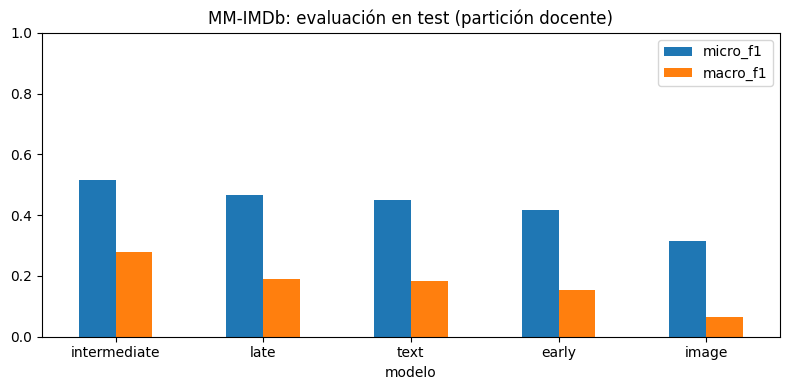

In [ ]:
results=[]; predictions={}
for mode, model in models_fit.items():
    yt, probs = predict(model,test_loader)
    if mode=='late': probs=alpha*probs[0]+(1-alpha)*probs[1]
    predictions[mode]=probs
    results.append({'modelo':mode,**scores(yt,probs)})
results_df=pd.DataFrame(results).sort_values('macro_f1',ascending=False)
display(results_df)
if not results_df.empty:
    results_df.set_index('modelo')[['micro_f1','macro_f1']].plot.bar(figsize=(8,4),ylim=(0,1),rot=0)
    plt.title('MM-IMDb: evaluación en test (partición docente)'); plt.tight_layout(); plt.show()


## 9. Métricas por género y análisis de errores

Se presenta el reporte por etiqueta del modelo con mejor Macro-F1. Los géneros poco frecuentes pueden obtener F1=0; esto no significa necesariamente que el modelo sea defectuoso: revise cuántos ejemplos positivos hay por categoría.

In [ ]:
best_mode=results_df.iloc[0]['modelo']
print('Mejor modelo (macro-F1 en test, SOLO descriptivo):',best_mode)
print(classification_report(yt,(predictions[best_mode]>=.5).astype(int),target_names=mlb.classes_,zero_division=0))


Mejor modelo (macro-F1 en test, SOLO descriptivo): intermediate
              precision    recall  f1-score   support

      Action       0.52      0.62      0.56        26
   Adventure       0.25      0.09      0.13        23
   Animation       0.71      0.71      0.71         7
   Biography       0.00      0.00      0.00         8
      Comedy       0.65      0.71      0.68        56
       Crime       0.47      0.24      0.32        29
 Documentary       0.80      0.50      0.62        16
       Drama       0.74      0.72      0.73        98
      Family       0.50      0.27      0.35        11
     Fantasy       0.23      0.21      0.22        14
   Film-Noir       0.00      0.00      0.00         3
     History       0.00      0.00      0.00         7
      Horror       0.42      0.31      0.36        16
       Music       0.00      0.00      0.00         6
     Musical       0.00      0.00      0.00         5
     Mystery       0.12      0.13      0.12        15
     Romance     

## 10. Guardar resultados y reproducibilidad

Se guardan métricas, nombres de etiquetas, índices del subconjunto y configuración. **Advertencia:** los índices son posiciones dentro de los datos leídos y no equivalen a IDs oficiales de MM-IMDb. Para reusar exactamente los splits, preserve el mismo origen, orden de lectura y semilla; para un experimento publicable recupere los splits oficiales por identificador de película.


In [ ]:
import json
from pathlib import Path
OUT=Path('resultados_mmimdb'); OUT.mkdir(exist_ok=True)
results_df.to_csv(OUT/'metricas_test.csv',index=False)
with open(OUT/'configuracion.json','w',encoding='utf-8') as f:
    json.dump({'repo_id':REPO_ID,'seed':SEED,'quick_mode':QUICK_MODE,'n_records':len(records),
               'freeze_encoders':FREEZE_ENCODERS,'epochs':EPOCHS,'batch_size':BATCH_SIZE,
               'max_length':MAX_LENGTH,'alpha_late':float(alpha),
               'classes':mlb.classes_.tolist(),
               'indices':{'train':list(map(int,idx_train)),'val':list(map(int,idx_val)),'test':list(map(int,idx_test))}},f,indent=2)
print('Archivos:',list(OUT.iterdir()))

Archivos: [PosixPath('resultados_mmimdb/metricas_test.csv'), PosixPath('resultados_mmimdb/configuracion.json')]


> ### 📝 **Ejercicio Práctico**
>
> **Instrucciones:** Otra forma de realizar la fusión intermedia es mediante ´compuertas de fusión´ (gated fusion). Investiga en qué consiste ésta estrategia, sus formulación matemática e interpretación. Básate en el artículo

> - Arevalo et al. (2017), *Gated Multimodal Units for Information Fusion*: https://arxiv.org/abs/1702.01992
>
> *⏱️ Tiempo estimado: 10 minutos*

> ### 📝 **Ejercicio Práctico**
>
> **Instrucciones:** Implementa variantes de las arquitecturas usadas:
>
> - Implementando gated fusion
> - Otras variantes de la arquitectura o parámetros (tamaño del dataset, épocas, etc...)
>
> Compara los resultados con éste procedimiento estándar.

> *⏱️ Tiempo estimado: 15 minutos*

## 12. Aprendizaje contrastivo entre póster y sinopsis

Como extensión de los clasificadores anteriores, podemos aprender una **representación compartida** de las dos modalidades sin utilizar los géneros como etiquetas. Cada película aporta un par positivo: su póster y su sinopsis. Los otros pósteres y sinopsis del mismo lote se usan como negativos. El objetivo es que la representación de un póster sea más similar a la de su propia sinopsis que a la de las demás.

**Arquitectura.** Usaremos los encoders unimodales anteriores: ResNet-18 produce un vector de 512 dimensiones y BERT (`[CLS]`) uno de 768. Mantendremos ambos encoders congelados y entrenaremos dos cabezas de proyección independientes hacia un espacio común de `CONTRASTIVE_DIM` dimensiones. Normalizaremos los vectores a norma 1 para que su producto punto sea la similitud coseno. Este diseño sigue la idea de CLIP, aunque aquí utilizamos ResNet-18 y BERT, y solo entrenamos las proyecciones. [CLIP: Radford et al., 2021](https://arxiv.org/abs/2103.00020).

Para un lote de tamaño $B$, calculamos la matriz $S_{ij}=z_i^{(imagen)}\cdot z_j^{(texto)}/\tau$. Su diagonal contiene los pares correctos. La **función de costo contrastiva simétrica** es

$$\mathcal{L}=-\frac{1}{2B}\sum_{i=1}^{B}\left[\log\frac{e^{S_{ii}}}{\sum_{j=1}^{B}e^{S_{ij}}}+\log\frac{e^{S_{ii}}}{\sum_{j=1}^{B}e^{S_{ji}}}\right].$$

Aquí $\tau$ es la temperatura y $S_{ii}$ representa la similitud del póster $i$ con su propia sinopsis. El primer término compara esa sinopsis con todas las del lote para el mismo póster; el segundo compara ese póster con todos los del lote para la misma sinopsis. Así, la pérdida favorece los pares correctos de la diagonal frente a los demás. En el código, `torch.arange(B)` genera los índices de esos pares correctos: para $B=4$, son `0, 1, 2, 3`. Los géneros `labels` no intervienen en esta pérdida.

**Interpretación:** el ejercicio permite inspeccionar si ambas modalidades se alinean, pero los negativos por lote pueden compartir género, actores o contenido. Además, con `QUICK_MODE=True` y encoders congelados, las métricas de recuperación solo describen este subconjunto; no son una evaluación exhaustiva. Usaremos `train` para aprender, `val` para escoger la mejor época y `test` únicamente para visualizar la representación final.

In [ ]:
# Liberar memoria del acelerador de procesamiento después de evaluar los clasificadores.
for classifier_model in models_fit.values():
    classifier_model.to("cpu")
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

import torch.nn.functional as F
from sklearn.decomposition import PCA

CONTRASTIVE_DIM = 128
CONTRASTIVE_TEMPERATURE = 0.07
CONTRASTIVE_BATCH_SIZE = 16  # Más pares por lote proporcionan más negativos; reducir si falta memoria.
CONTRASTIVE_EPOCHS = 2 if QUICK_MODE else 5
CONTRASTIVE_LR = 1e-3

contrastive_train_loader = DataLoader(
    MovieDataset(idx_train), batch_size=CONTRASTIVE_BATCH_SIZE,
    shuffle=True, num_workers=NUM_WORKERS, drop_last=True
)
contrastive_val_loader = DataLoader(
    MovieDataset(idx_val), batch_size=CONTRASTIVE_BATCH_SIZE,
    shuffle=False, num_workers=NUM_WORKERS
)
contrastive_test_loader = DataLoader(
    MovieDataset(idx_test), batch_size=CONTRASTIVE_BATCH_SIZE,
    shuffle=False, num_workers=NUM_WORKERS
)

class MovieContrastive(nn.Module):
    def __init__(self, projection_dim=CONTRASTIVE_DIM):
        super().__init__()
        self.enc = Encoders(freeze=True)
        self.image_projection = nn.Linear(512, projection_dim)
        self.text_projection = nn.Linear(768, projection_dim)

    def forward(self, batch):
        image_features, text_features = self.enc(batch)
        image_z = F.normalize(self.image_projection(image_features), dim=-1)
        text_z = F.normalize(self.text_projection(text_features), dim=-1)
        return image_z, text_z

def contrastive_loss(image_z, text_z, temperature=CONTRASTIVE_TEMPERATURE):
    logits = image_z @ text_z.T / temperature
    targets = torch.arange(len(image_z), device=logits.device)
    loss_image_to_text = F.cross_entropy(logits, targets)
    loss_text_to_image = F.cross_entropy(logits.T, targets)
    return (loss_image_to_text + loss_text_to_image) / 2

print('Número de pares en train/val/test:',
      len(idx_train), len(idx_val), len(idx_test))


Número de pares en train/val/test: 837 179 184


### Entrenamiento y selección de las épocas

Entrenaremos únicamente las dos proyecciones. Al terminar cada época, mediremos la pérdida en `val` y conservaremos el estado con menor pérdida de validación. Así evitamos usar `test` para ajustar el modelo. La pérdida depende del número y de la composición de los negativos en cada lote; conviene comparar experimentos con la misma configuración.

In [ ]:
contrastive_model = MovieContrastive().to(DEVICE)
contrastive_optimizer = torch.optim.AdamW(
    (p for p in contrastive_model.parameters() if p.requires_grad),
    lr=CONTRASTIVE_LR, weight_decay=0.01
)
contrastive_history = []
best_val_loss = float('inf')
best_contrastive_state = None

for epoch in range(CONTRASTIVE_EPOCHS):
    contrastive_model.train()
    train_loss_sum = 0.0
    train_pairs = 0
    for raw in tqdm(contrastive_train_loader, desc=f'Contrastive epoch {epoch + 1}', leave=False):
        batch = {key: value.to(DEVICE) for key, value in raw.items()}
        contrastive_optimizer.zero_grad(set_to_none=True)
        image_z, text_z = contrastive_model(batch)
        loss = contrastive_loss(image_z, text_z)
        loss.backward()
        contrastive_optimizer.step()
        train_loss_sum += loss.item() * len(image_z)
        train_pairs += len(image_z)

    contrastive_model.eval()
    val_loss_sum = 0.0
    val_pairs = 0
    with torch.no_grad():
        for raw in contrastive_val_loader:
            batch = {key: value.to(DEVICE) for key, value in raw.items()}
            image_z, text_z = contrastive_model(batch)
            loss = contrastive_loss(image_z, text_z)
            val_loss_sum += loss.item() * len(image_z)
            val_pairs += len(image_z)

    train_loss = train_loss_sum / train_pairs
    val_loss = val_loss_sum / val_pairs
    contrastive_history.append({'epoch': epoch + 1, 'train_loss': train_loss, 'val_loss': val_loss})
    print(f'Epoch {epoch + 1}: train={train_loss:.4f}, val={val_loss:.4f}')
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_contrastive_state = {
            key: value.detach().cpu().clone()
            for key, value in contrastive_model.state_dict().items()
            if key.startswith(('image_projection.', 'text_projection.'))
        }

contrastive_model.load_state_dict(best_contrastive_state, strict=False)
contrastive_history = pd.DataFrame(contrastive_history)
display(contrastive_history)


Contrastive epoch 1:   0%|          | 0/52 [00:00<?, ?it/s]

Epoch 1: train=2.7532, val=2.6288


Contrastive epoch 2:   0%|          | 0/52 [00:00<?, ?it/s]

Epoch 2: train=2.1785, val=2.7395


,epoch,train_loss,val_loss
0,1,2.753157,2.628755
1,2,2.178496,2.739462


### Visualización de la representación compartida

Extraeremos los embeddings del conjunto `test` y mediremos **Recall@1** en ambos sentidos: para cada póster, si su sinopsis es la más similar; y para cada sinopsis, si su póster es el más similar. Es una tarea de recuperación de pares, distinta de la clasificación de géneros. La matriz de similitud muestra los pares correctos en la diagonal.

La gráfica PCA proyecta los embeddings de ambas modalidades al mismo plano; las líneas unen algunos pares verdaderos. PCA es solo una visualización bidimensional: las distancias y posiciones del plano no sustituyen a las similitudes calculadas en las `CONTRASTIVE_DIM` dimensiones originales.

Test image→text Recall@1: 0.027
Test text→image Recall@1: 0.022
Referencia aleatoria aproximada: 0.005


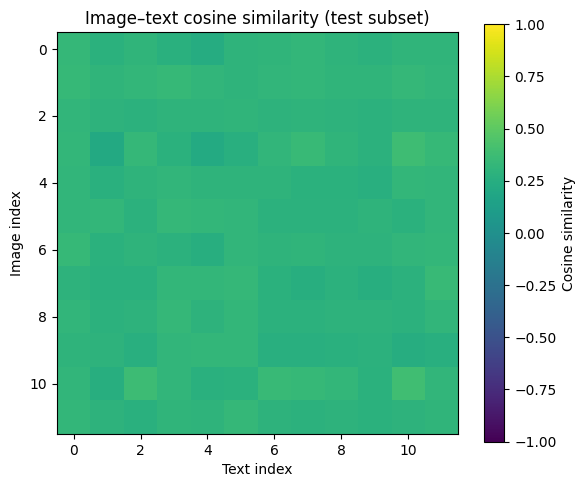

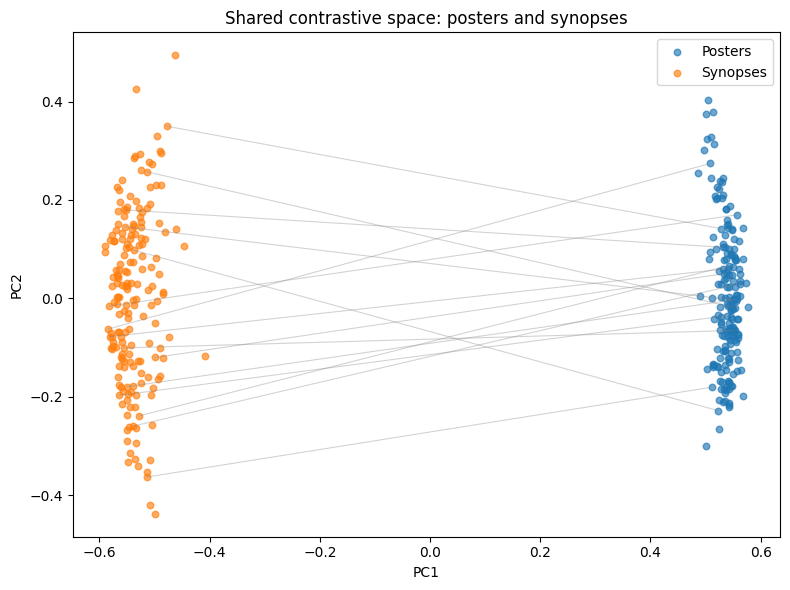

In [ ]:
@torch.no_grad()
def extract_contrastive_embeddings(model, loader):
    model.eval()
    image_parts, text_parts = [], []
    for raw in loader:
        batch = {key: value.to(DEVICE) for key, value in raw.items()}
        image_z, text_z = model(batch)
        image_parts.append(image_z.cpu())
        text_parts.append(text_z.cpu())
    return torch.cat(image_parts).numpy(), torch.cat(text_parts).numpy()

test_image_z, test_text_z = extract_contrastive_embeddings(
    contrastive_model, contrastive_test_loader
)
similarity = test_image_z @ test_text_z.T
targets = np.arange(len(similarity))
recall_image_to_text = np.mean(similarity.argmax(axis=1) == targets)
recall_text_to_image = np.mean(similarity.argmax(axis=0) == targets)
print(f'Test image→text Recall@1: {recall_image_to_text:.3f}')
print(f'Test text→image Recall@1: {recall_text_to_image:.3f}')
print(f'Referencia aleatoria aproximada: {1 / len(similarity):.3f}')

n_show = min(12, len(similarity))
fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(similarity[:n_show, :n_show], cmap='viridis', vmin=-1, vmax=1)
ax.set(xlabel='Text index', ylabel='Image index',
       title='Image–text cosine similarity (test subset)')
fig.colorbar(image, ax=ax, label='Cosine similarity')
plt.tight_layout()
plt.show()

joint_embeddings = np.vstack([test_image_z, test_text_z])
coordinates = PCA(n_components=2).fit_transform(joint_embeddings)
n_pairs = len(test_image_z)
image_xy, text_xy = coordinates[:n_pairs], coordinates[n_pairs:]
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(image_xy[:, 0], image_xy[:, 1], s=22, alpha=0.65,
           label='Posters')
ax.scatter(text_xy[:, 0], text_xy[:, 1], s=22, alpha=0.65,
           label='Synopses')
for i in range(min(15, n_pairs)):
    ax.plot([image_xy[i, 0], text_xy[i, 0]],
            [image_xy[i, 1], text_xy[i, 1]],
            color='gray', alpha=0.35, linewidth=0.8)
ax.set(xlabel='PC1', ylabel='PC2',
       title='Shared contrastive space: posters and synopses')
ax.legend()
plt.tight_layout()
plt.show()

# Conservar el modelo entrenado en CPU para liberar memoria del acelerador.
contrastive_model.to('cpu')
if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()


## 13. Aprendizaje contrastivo supervisado por género (por revisar)

La sección anterior trató como positivo **solo** el par póster–sinopsis de la misma película. Aquí añadiremos una señal supervisada: también trataremos como positivos los pares imagen–texto de **películas diferentes del mismo género**. Las películas de los otros géneros del lote serán negativos. Queremos observar si los pósteres y las sinopsis se agrupan por género en un espacio compartido.

**Selección de datos.** Elegimos los tres géneros más frecuentes **usando solo `train`**. Como MM-IMDb es multietiqueta, conservamos las películas que tienen **exactamente uno de esos tres géneros**. Pueden tener además géneros que no estén entre los tres seleccionados; esto define una etiqueta clara para esta práctica, pero no convierte el problema original en una clasificación exclusiva de todos sus géneros. Aplicamos la misma regla a `val` y `test`, sin volver a elegir los géneros.

**Arquitectura.** Partimos del modelo contrastivo de la sección 12: ResNet-18 y BERT permanecen congelados, y seguimos entrenando sus dos proyecciones lineales hacia el espacio compartido. Partir de las proyecciones ya entrenadas permite comparar la representación antes y después de incorporar la información de género.

**Función de costo.** Para el póster $i$, sea $P(i)$ el conjunto de sinopsis del lote con el **mismo género seleccionado**. Si $S_{ij}$ es la similitud del póster $i$ con la sinopsis $j$, dividida entre la temperatura, la pérdida imagen→texto es

$$\mathcal{L}_{I\to T}=-\frac{1}{B}\sum_{i=1}^{B}\frac{1}{|P(i)|}\sum_{j\in P(i)}\log\frac{e^{S_{ij}}}{\sum_{k=1}^{B}e^{S_{ik}}}.$$

Calculamos del mismo modo $\mathcal{L}_{T\to I}$ intercambiando imágenes y textos, y usamos $\mathcal{L}=(\mathcal{L}_{I\to T}+\mathcal{L}_{T\to I})/2$. Cada película garantiza al menos un positivo: su propia sinopsis. Esta es una variante supervisada de la pérdida contrastiva; **no garantiza** que todas las películas de un género sean visual o semánticamente parecidas. [Supervised Contrastive Learning: Khosla et al., 2020](https://arxiv.org/abs/2004.11362).

In [ ]:
from torch.utils.data import WeightedRandomSampler

class GenreMovieDataset(MovieDataset):
    def __init__(self, indices, genre_ids):
        super().__init__(indices)
        self.genre_ids = np.asarray(genre_ids)

    def __getitem__(self, i):
        example = super().__getitem__(i)
        example['genre_ids'] = torch.tensor(int(self.genre_ids[i]), dtype=torch.long)
        return example

top_genre_columns = np.argsort(-Y[np.asarray(idx_train)].sum(axis=0))[:3]
top_genre_names = mlb.classes_[top_genre_columns]

def select_one_top_genre(indices):
    indices = np.asarray(indices)
    selected_labels = Y[indices][:, top_genre_columns]
    keep = selected_labels.sum(axis=1) == 1
    selected_indices = indices[keep]
    genre_ids = selected_labels[keep].argmax(axis=1).astype(int)
    return selected_indices, genre_ids

genre_idx_train, genre_y_train = select_one_top_genre(idx_train)
genre_idx_val, genre_y_val = select_one_top_genre(idx_val)
genre_idx_test, genre_y_test = select_one_top_genre(idx_test)

for split_name, genre_ids in [('train', genre_y_train), ('val', genre_y_val), ('test', genre_y_test)]:
    counts = np.bincount(genre_ids, minlength=3)
    print(split_name, len(genre_ids), dict(zip(top_genre_names, counts)))

assert len(genre_idx_train) >= CONTRASTIVE_BATCH_SIZE
assert len(genre_idx_val) > 0 and len(genre_idx_test) > 0
assert np.all(np.bincount(genre_y_train, minlength=3) > 0), "Increase N_QUICK: a selected genre is missing from train."
assert np.all(np.bincount(genre_y_test, minlength=3) > 0), "Increase N_QUICK: a selected genre is missing from test."

# Muestrear las tres clases con frecuencia aproximadamente igual en train.
genre_counts_train = np.bincount(genre_y_train, minlength=3)
sampling_weights = torch.as_tensor(1.0 / genre_counts_train[genre_y_train], dtype=torch.double)
genre_sampler = WeightedRandomSampler(
    sampling_weights, num_samples=len(genre_y_train), replacement=True
)
genre_train_loader = DataLoader(
    GenreMovieDataset(genre_idx_train, genre_y_train), batch_size=CONTRASTIVE_BATCH_SIZE,
    sampler=genre_sampler, num_workers=NUM_WORKERS, drop_last=True
)
genre_val_loader = DataLoader(
    GenreMovieDataset(genre_idx_val, genre_y_val), batch_size=CONTRASTIVE_BATCH_SIZE,
    shuffle=False, num_workers=NUM_WORKERS
)
genre_test_loader = DataLoader(
    GenreMovieDataset(genre_idx_test, genre_y_test), batch_size=CONTRASTIVE_BATCH_SIZE,
    shuffle=False, num_workers=NUM_WORKERS
)


train 482 {'Drama': np.int64(263), 'Comedy': np.int64(145), 'Thriller': np.int64(74)}
val 103 {'Drama': np.int64(55), 'Comedy': np.int64(34), 'Thriller': np.int64(14)}
test 108 {'Drama': np.int64(63), 'Comedy': np.int64(33), 'Thriller': np.int64(12)}


### Entrenamiento con positivos del mismo género

Cada lote usa una máscara de positivos basada en los géneros seleccionados. La máscara incluye la diagonal (cada póster y su propia sinopsis) y los pares de películas distintas que comparten género. Entrenamos con `train`, escogemos la mejor época con `val` y reservamos `test` para la comparación visual y las métricas descriptivas. El muestreo ponderado de `train` ayuda a que los tres géneros aparezcan con frecuencia similar en los lotes.

In [ ]:
def supervised_cross_modal_loss(image_z, text_z, genre_ids, temperature=CONTRASTIVE_TEMPERATURE):
    logits = image_z @ text_z.T / temperature
    positives = genre_ids[:, None].eq(genre_ids[None, :]).float()
    positives_per_row = positives.sum(dim=1)
    image_to_text = -(positives * F.log_softmax(logits, dim=1)).sum(dim=1) / positives_per_row
    text_to_image = -(positives * F.log_softmax(logits.T, dim=1)).sum(dim=1) / positives_per_row
    return (image_to_text.mean() + text_to_image.mean()) / 2

genre_contrastive_model = copy.deepcopy(contrastive_model).to(DEVICE)
genre_optimizer = torch.optim.AdamW(
    (p for p in genre_contrastive_model.parameters() if p.requires_grad),
    lr=CONTRASTIVE_LR, weight_decay=0.01
)
genre_epochs = 2 if QUICK_MODE else 5
genre_history = []
best_genre_val_loss = float('inf')
best_genre_projection_state = None

for epoch in range(genre_epochs):
    genre_contrastive_model.train()
    train_loss_sum = 0.0
    train_count = 0
    for raw in tqdm(genre_train_loader, desc=f'Genre contrastive epoch {epoch + 1}', leave=False):
        batch = {key: value.to(DEVICE) for key, value in raw.items()}
        genre_optimizer.zero_grad(set_to_none=True)
        image_z, text_z = genre_contrastive_model(batch)
        loss = supervised_cross_modal_loss(image_z, text_z, batch['genre_ids'])
        loss.backward()
        genre_optimizer.step()
        train_loss_sum += loss.item() * len(image_z)
        train_count += len(image_z)

    genre_contrastive_model.eval()
    val_loss_sum = 0.0
    val_count = 0
    with torch.no_grad():
        for raw in genre_val_loader:
            batch = {key: value.to(DEVICE) for key, value in raw.items()}
            image_z, text_z = genre_contrastive_model(batch)
            loss = supervised_cross_modal_loss(image_z, text_z, batch['genre_ids'])
            val_loss_sum += loss.item() * len(image_z)
            val_count += len(image_z)

    train_loss = train_loss_sum / train_count
    val_loss = val_loss_sum / val_count
    genre_history.append({'epoch': epoch + 1, 'train_loss': train_loss, 'val_loss': val_loss})
    print(f'Epoch {epoch + 1}: train={train_loss:.4f}, val={val_loss:.4f}')
    if val_loss < best_genre_val_loss:
        best_genre_val_loss = val_loss
        best_genre_projection_state = {
            key: value.detach().cpu().clone()
            for key, value in genre_contrastive_model.state_dict().items()
            if key.startswith(('image_projection.', 'text_projection.'))
        }

genre_contrastive_model.load_state_dict(best_genre_projection_state, strict=False)
genre_history = pd.DataFrame(genre_history)
display(genre_history)


Genre contrastive epoch 1:   0%|          | 0/30 [00:00<?, ?it/s]

Epoch 1: train=2.7383, val=2.7217


Genre contrastive epoch 2:   0%|          | 0/30 [00:00<?, ?it/s]

Epoch 2: train=2.6313, val=2.8077


,epoch,train_loss,val_loss
0,1,2.738328,2.721735
1,2,2.631308,2.807723


### Alineación imagen–texto por género

Compararemos la representación de la sección 12 con la representación ajustada por género. Para cada póster del subconjunto `test`, elegimos la sinopsis más similar y comprobamos si pertenece al **mismo género seleccionado**; repetimos en el sentido inverso. Esta métrica no exige recuperar la sinopsis de la misma película. También calculamos la diferencia entre la similitud media de pares del mismo género y la de pares de géneros distintos; un valor mayor indica mejor separación por género. Después mostraremos una matriz de similitud entre los centroides de los tres géneros y una proyección PCA conjunta de imágenes y textos. Los colores indican el género seleccionado y los símbolos, la modalidad. Una proyección PCA puede ocultar relaciones del espacio completo, por lo que conviene leerla junto con las similitudes y las métricas.

,representation,image_to_text_genre_accuracy,text_to_image_genre_accuracy,same_minus_other_genre_similarity
0,Pair-only contrastive,0.509,0.509,0.004
1,Genre-supervised contrastive,0.602,0.602,0.009


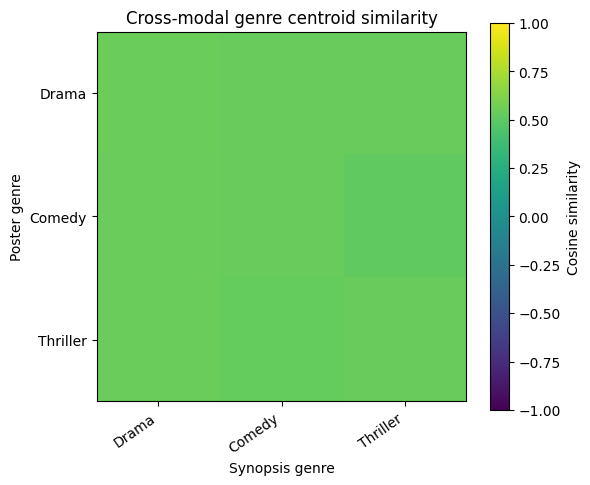

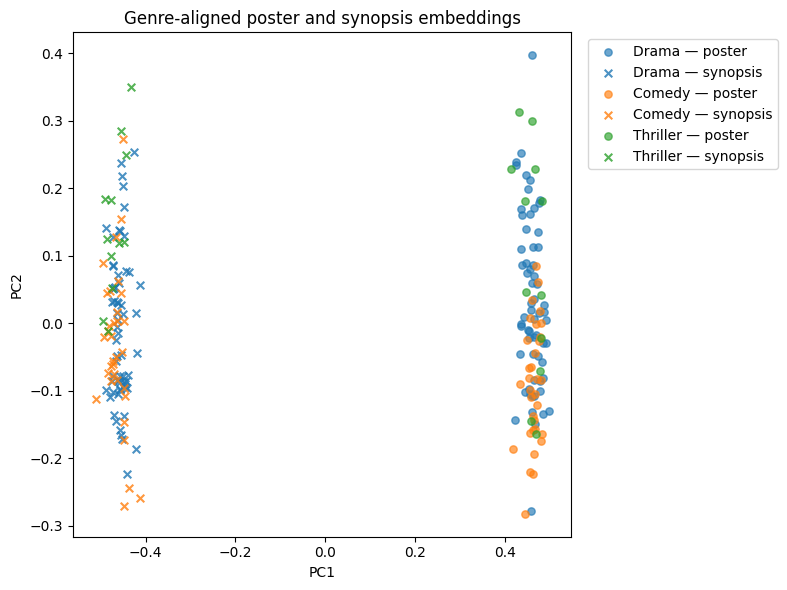

In [ ]:
genre_test_image_z, genre_test_text_z = extract_contrastive_embeddings(
    genre_contrastive_model, genre_test_loader
)
test_positions = np.flatnonzero(np.isin(np.asarray(idx_test), genre_idx_test))
base_genre_image_z = test_image_z[test_positions]
base_genre_text_z = test_text_z[test_positions]
assert len(genre_y_test) == len(genre_test_image_z) == len(base_genre_image_z)

def cross_modal_genre_accuracy(image_z, text_z, genre_ids):
    similarities = image_z @ text_z.T
    image_to_text = np.mean(genre_ids[similarities.argmax(axis=1)] == genre_ids)
    text_to_image = np.mean(genre_ids[similarities.argmax(axis=0)] == genre_ids)
    return image_to_text, text_to_image

before_scores = cross_modal_genre_accuracy(
    base_genre_image_z, base_genre_text_z, genre_y_test
)
after_scores = cross_modal_genre_accuracy(
    genre_test_image_z, genre_test_text_z, genre_y_test
)
def genre_similarity_gap(image_z, text_z, genre_ids):
    similarities = image_z @ text_z.T
    same_genre = genre_ids[:, None] == genre_ids[None, :]
    return similarities[same_genre].mean() - similarities[~same_genre].mean()

display(pd.DataFrame({
    'representation': ['Pair-only contrastive', 'Genre-supervised contrastive'],
    'image_to_text_genre_accuracy': [before_scores[0], after_scores[0]],
    'text_to_image_genre_accuracy': [before_scores[1], after_scores[1]],
    'same_minus_other_genre_similarity': [
        genre_similarity_gap(base_genre_image_z, base_genre_text_z, genre_y_test),
        genre_similarity_gap(genre_test_image_z, genre_test_text_z, genre_y_test)
    ],
}).round(3))

image_centroids = []
text_centroids = []
for genre_id in range(3):
    mask = genre_y_test == genre_id
    image_centroids.append(genre_test_image_z[mask].mean(axis=0))
    text_centroids.append(genre_test_text_z[mask].mean(axis=0))
image_centroids = F.normalize(torch.tensor(np.stack(image_centroids)), dim=1).numpy()
text_centroids = F.normalize(torch.tensor(np.stack(text_centroids)), dim=1).numpy()
centroid_similarity = image_centroids @ text_centroids.T

fig, ax = plt.subplots(figsize=(6, 5))
heatmap = ax.imshow(centroid_similarity, vmin=-1, vmax=1, cmap='viridis')
ax.set_xticks(range(3), top_genre_names, rotation=35, ha='right')
ax.set_yticks(range(3), top_genre_names)
ax.set(xlabel='Synopsis genre', ylabel='Poster genre',
       title='Cross-modal genre centroid similarity')
fig.colorbar(heatmap, ax=ax, label='Cosine similarity')
plt.tight_layout()
plt.show()

joint = np.vstack([genre_test_image_z, genre_test_text_z])
xy = PCA(n_components=2).fit_transform(joint)
n_test_genre = len(genre_y_test)
fig, ax = plt.subplots(figsize=(8, 6))
colors = plt.get_cmap('tab10').colors
for genre_id, genre_name in enumerate(top_genre_names):
    mask = genre_y_test == genre_id
    ax.scatter(xy[:n_test_genre][mask, 0], xy[:n_test_genre][mask, 1],
               color=colors[genre_id], marker='o', s=28, alpha=0.65,
               label=f'{genre_name} — poster')
    ax.scatter(xy[n_test_genre:][mask, 0], xy[n_test_genre:][mask, 1],
               color=colors[genre_id], marker='x', s=30, alpha=0.8,
               label=f'{genre_name} — synopsis')
ax.set(xlabel='PC1', ylabel='PC2',
       title='Genre-aligned poster and synopsis embeddings')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

genre_contrastive_model.to('cpu')
if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()
